# Natural-Flow Adequacy Prediction in Solution-Gas-Drive Reservoirs

## Supervisor-facing notebook guide
This notebook is the first executable modeling stage. It demonstrates loading, canonicalizing, auditing, engineering lagged history features, defining a transparent natural-flow threshold event, and evaluating fixed-horizon oil-rate prediction on held-out wells. The included data are synthetic and only verify that the workflow runs. No performance number from the synthetic sample is evidence of field accuracy.

### Research objective
Estimate future production and pressure behavior from reservoir type, generalized place/region, history, and current operating/reservoir measurements. The current prototype focuses on rate forecasting and event construction. A validated time-to-inadequacy probability model requires field records with documented lift status and operational/economic threshold.

### Running cell by cell
Run each cell in order. Set `DATA_PATH` to your file and complete `COLUMN_MAP` and `UNIT_MAP` before using field data. Accepted files are CSV, XLSX/XLS, Parquet, and JSON. Arbitrary file formats cannot be interpreted safely without a parser and a column/unit mapping.

## 1. Environment and project imports
The import cell loads the local project package. If dependencies are missing, install `requirements.txt` from the repository root before continuing.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from sgd_ml.io import load_table
from sgd_ml.features import normalize_columns, engineer_history
from sgd_ml.labels import add_forward_targets, label_inadequacy
from sgd_ml.modeling import split_by_well, split_by_time, make_regressor, evaluate_regression

## 2. Data source and explicit mappings
A canonical table requires `well_id`, `date`, and `oil_rate`. Column mapping renames source columns. Record units separately; mapping a column name does not convert units. Geography should be generalized if exact location is sensitive.

In [2]:
DATA_PATH = PROJECT_ROOT / "data/synthetic/demo_well_monthly.csv"
COLUMN_MAP = {
    "year": "year",
    "month": "month",
}
UNIT_MAP = {"oil_rate": "volume/day", "gas_rate": "volume/day", "water_rate": "volume/day", "reservoir_pressure": "pressure", "bhp": "pressure"}
raw = load_table(DATA_PATH)
if {"year", "month"}.issubset(raw.columns) and "date" not in raw.columns:
    raw["date"] = pd.to_datetime(raw["year"].astype(str) + "-" + raw["month"].astype(str) + "-01", errors="coerce")
print(f"Loaded {len(raw):,} observations from {raw['well_id'].nunique():,} wells")
raw.head()

Loaded 2,592 observations from 36 wells


,well_id,year,month,region,reservoir_type,oil_rate,gas_rate,water_rate,reservoir_pressure,bhp,bubble_point_pressure,initial_reservoir_pressure,gor,water_cut,choke,cumulative_oil,lift_active,date
0,SYN-001,2016,1,South,solution_gas_drive,364.664681,75399.081038,8.751485,2899.551385,2782.297641,2498.920396,2898.026745,206.762774,0.023436,32.996456,0.000000,False,2016-01-01
1,SYN-001,2016,2,South,solution_gas_drive,364.586267,121063.311662,5.236564,2878.155708,2710.809682,2498.920396,2898.026745,332.056697,0.014160,36.293899,364.586267,False,2016-02-01
2,SYN-001,2016,3,South,solution_gas_drive,341.563859,92949.411327,10.654900,2835.738374,2633.701682,2498.920396,2898.026745,272.128941,0.030251,57.254411,683.127718,False,2016-03-01
3,SYN-001,2016,4,South,solution_gas_drive,319.804285,94883.345054,11.573919,2815.057537,2632.598599,2498.920396,2898.026745,296.691912,0.034927,22.694025,959.412856,False,2016-04-01
4,SYN-001,2016,5,South,solution_gas_drive,318.415304,96126.444389,6.845260,2864.167346,2629.005059,2498.920396,2898.026745,301.890152,0.021045,44.299718,1273.661215,False,2016-05-01


## 3. Schema and quality audit
The audit reports missingness and duplicate well-date records before feature construction. Duplicate observations need engineering resolution, not blind averaging. Check whether the production frequency is regular and whether rates are measured, allocated, or estimated.

In [3]:
required = {"well_id", "date", "oil_rate"}
missing = required.difference(raw.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")
duplicate_count = raw.duplicated(["well_id", "date"]).sum()
quality = pd.DataFrame({"missing_count": raw.isna().sum(), "missing_fraction": raw.isna().mean()})
print(f"Duplicate well-date rows: {duplicate_count}")
display(quality.sort_values("missing_fraction", ascending=False))

Duplicate well-date rows: 0


,missing_count,missing_fraction
well_id,0,0.0
year,0,0.0
month,0,0.0
region,0,0.0
reservoir_type,0,0.0
oil_rate,0,0.0
gas_rate,0,0.0
water_rate,0,0.0
reservoir_pressure,0,0.0
bhp,0,0.0


## 4. Canonicalizing columns and checking measurement coverage
Replace the illustrative mapping with the source dataset's verified names. The following line expects canonical names to already exist in the sample. Use explicit mappings for a field file and convert units before combining sources.

In [4]:
df = normalize_columns(raw)
for col in ["oil_rate", "gas_rate", "water_rate", "reservoir_pressure", "bhp", "water_cut", "gor"]:
    if col in df:
        df[col] = pd.to_numeric(df[col], errors="coerce")
print("Well count:", df.well_id.nunique())
print("Time span:", df.date.min().date(), "to", df.date.max().date())
display(df.groupby("reservoir_type", dropna=False).agg(wells=("well_id", "nunique"), rows=("well_id", "size")) if "reservoir_type" in df else df.groupby("well_id").size().describe())

Well count: 36
Time span: 2012-01-01 to 2025-12-01


,wells,rows
reservoir_type,,
gas_cap,13,936
solution_gas_drive,5,360
water_drive,18,1296


## 5. Engineering lagged production and pressure features
Features use values available up to the observation time. Shifted rolling summaries avoid including the current target measurement in historical predictors. Calendar and elapsed-time variables support trend context. For irregular measurements, resample to a documented cadence before applying period windows.

In [5]:
featured = engineer_history(df, windows=(3, 6, 12))
print("Engineered table:", featured.shape)
featured.filter(regex="(lag1|mean3|slope3|pressure_minus_bubble_point)$").head()

Engineered table: (2592, 69)


,oil_rate_lag1,oil_rate_mean3,oil_rate_slope3,gas_rate_lag1,gas_rate_mean3,gas_rate_slope3,water_rate_lag1,water_rate_mean3,water_rate_slope3,reservoir_pressure_lag1,...,gor_lag1,gor_mean3,gor_slope3,choke_lag1,choke_mean3,choke_slope3,cumulative_oil_lag1,cumulative_oil_mean3,cumulative_oil_slope3,pressure_minus_bubble_point
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,400.630990
1,364.664681,364.664681,NaN,75399.081038,75399.081038,NaN,8.751485,8.751485,NaN,2899.551385,...,206.762774,206.762774,NaN,32.996456,32.996456,NaN,0.000000,0.000000,NaN,379.235312
2,364.586267,364.625474,NaN,121063.311662,98231.196350,NaN,5.236564,6.994024,NaN,2878.155708,...,332.056697,269.409736,NaN,36.293899,34.645177,NaN,364.586267,182.293133,NaN,336.817979
3,341.563859,356.938269,-11.550411,92949.411327,96470.601342,8775.165145,10.654900,8.214316,0.951708,2835.738374,...,272.128941,270.316138,32.683084,57.254411,42.181588,12.128977,683.127718,349.237995,341.563859,316.137142
4,319.804285,341.984804,-22.390991,94883.345054,102965.356014,-13089.983304,11.573919,9.155128,3.168678,2815.057537,...,296.691912,300.292517,-17.682393,22.694025,38.747445,-6.799937,959.412856,669.042280,297.413295,365.246950


## 6. Defining the inadequacy event
The 10-unit/day value below is an example only. The team must select and document a threshold using operating constraints and economic assumptions. Two consecutive periods reduce single-period noise but do not solve data-quality or shut-in issues. Shut-ins and lift-active periods are excluded from the natural-flow interpretation.

In [6]:
NATURAL_FLOW_THRESHOLD = 10.0
CONSECUTIVE_PERIODS = 2
labeled = label_inadequacy(featured, threshold=NATURAL_FLOW_THRESHOLD, min_consecutive=CONSECUTIVE_PERIODS)
print("Rows marked at first sustained threshold crossing:", int(labeled.inadequate_now.sum()))

Rows marked at first sustained threshold crossing: 4


## 7. Defining forecast labels and leakage controls
This example predicts oil rate three observations ahead. For monthly data this means three months; confirm cadence. Features at the forecast origin must not include future measurements, post-transition values, future cumulative totals, or target-derived columns.

In [7]:
HORIZON = 3
labeled = add_forward_targets(labeled, horizons=(HORIZON,))
target = f"oil_rate_future_{HORIZON}m"
excluded = {"date", "well_id", "inadequate_now", target}
feature_cols = [c for c in labeled.select_dtypes(include=["number", "object", "bool"]).columns if c not in excluded and not c.startswith(("oil_rate_future", "reservoir_pressure_future", "months_to_inadequate"))]
model_data = labeled.dropna(subset=[target]).copy()
print("Candidate predictors including current production and pressure:", feature_cols)
print("Eligible forecast-origin rows:", len(model_data))

Candidate predictors including current production and pressure: ['year', 'month', 'region', 'reservoir_type', 'oil_rate', 'gas_rate', 'water_rate', 'reservoir_pressure', 'bhp', 'bubble_point_pressure', 'initial_reservoir_pressure', 'gor', 'water_cut', 'choke', 'cumulative_oil', 'lift_active', 'elapsed_days', 'elapsed_months', 'calendar_year', 'calendar_month', 'oil_rate_lag1', 'oil_rate_mean3', 'oil_rate_mean6', 'oil_rate_mean12', 'oil_rate_slope3', 'gas_rate_lag1', 'gas_rate_mean3', 'gas_rate_mean6', 'gas_rate_mean12', 'gas_rate_slope3', 'water_rate_lag1', 'water_rate_mean3', 'water_rate_mean6', 'water_rate_mean12', 'water_rate_slope3', 'reservoir_pressure_lag1', 'reservoir_pressure_mean3', 'reservoir_pressure_mean6', 'reservoir_pressure_mean12', 'reservoir_pressure_slope3', 'bhp_lag1', 'bhp_mean3', 'bhp_mean6', 'bhp_mean12', 'bhp_slope3', 'water_cut_lag1', 'water_cut_mean3', 'water_cut_mean6', 'water_cut_mean12', 'water_cut_slope3', 'gor_lag1', 'gor_mean3', 'gor_mean6', 'gor_mean12',

/tmp/ipykernel_7467/3174273238.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  feature_cols = [c for c in labeled.select_dtypes(include=["number", "object", "bool"]).columns if c not in excluded and not c.startswith(("oil_rate_future", "reservoir_pressure_future", "months_to_inadequate"))]


## 8. Holding out complete wells
The primary split evaluates transfer to wells not used in training. It does not replace a chronological holdout for future forecasting within known wells. With few wells, repeat grouped cross-validation and report uncertainty across splits. Never randomly split monthly rows.

In [8]:
train_df, test_df = split_by_well(model_data, test_size=0.25, seed=42)
X_train, y_train = train_df[feature_cols], train_df[target]
X_test, y_test = test_df[feature_cols], test_df[target]
model = make_regressor(X_train)
model.fit(X_train, y_train)
pred = model.predict(X_test)
metrics = evaluate_regression(y_test, pred)
metrics_table = pd.DataFrame([metrics]).assign(train_wells=train_df.well_id.nunique(), test_wells=test_df.well_id.nunique(), test_rows=len(test_df))
display(metrics_table)

,MAE,RMSE,R2,train_wells,test_wells,test_rows
0,5.237917,8.216966,0.979202,27,9,621


## 9.1. Forecasting later periods for already-known wells
The chronological split trains on earlier dates and tests on a later date block. Each well may appear on both sides, but test observations occur after the training cutoff. This approximates future prediction for existing wells and complements, rather than replaces, the unseen-well split. A production deployment would retrain only with historical records available at that origin.

In [9]:
time_train, time_test = split_by_time(model_data, test_fraction=0.2)
time_model = make_regressor(time_train[feature_cols])
time_model.fit(time_train[feature_cols], time_train[target])
time_pred = time_model.predict(time_test[feature_cols])
time_metrics = evaluate_regression(time_test[target], time_pred)
time_metrics_table = pd.DataFrame([time_metrics]).assign(train_wells=time_train.well_id.nunique(), test_wells=time_test.well_id.nunique(), test_rows=len(time_test), cutoff=time_test.date.min().date())
display(time_metrics_table)

,MAE,RMSE,R2,train_wells,test_wells,test_rows,cutoff
0,2.909464,4.376585,0.989677,36,17,511,2021-11-01


## 9. Forecast table and diagnostic charts
The table shows forecasts and errors in target units. Regression has no single meaningful accuracy percentage. MAE/RMSE must be compared with persistence and decline-curve baselines. R-squared can be negative on difficult holdouts and is not a standalone measure of operational usefulness.

,well_id,date,reservoir_type,region,oil_rate,oil_rate_future_3m,prediction,error,absolute_error
2161,SYN-031,2020-02-01,water_drive,North,348.093285,261.612373,343.955734,-82.343361,82.343361
2160,SYN-031,2020-01-01,water_drive,North,355.342257,279.000042,326.252992,-47.252949,47.252949
2520,SYN-036,2015-01-01,water_drive,South,274.253525,215.047892,249.325679,-34.277787,34.277787
2162,SYN-031,2020-03-01,water_drive,North,301.411053,262.088981,294.293574,-32.204593,32.204593
1517,SYN-022,2012-06-01,water_drive,Central,299.235017,220.947316,251.061424,-30.114108,30.114108
1877,SYN-027,2016-06-01,gas_cap,Central,239.094398,190.941961,219.601732,-28.659771,28.659771
2175,SYN-031,2021-04-01,water_drive,North,160.999057,119.943775,148.342267,-28.398492,28.398492
2171,SYN-031,2020-12-01,water_drive,North,201.943041,157.415823,185.575872,-28.160049,28.160049
1512,SYN-022,2012-01-01,water_drive,Central,390.989358,328.011123,355.677960,-27.666837,27.666837
1523,SYN-022,2012-12-01,water_drive,Central,209.974868,167.105897,194.461338,-27.355441,27.355441


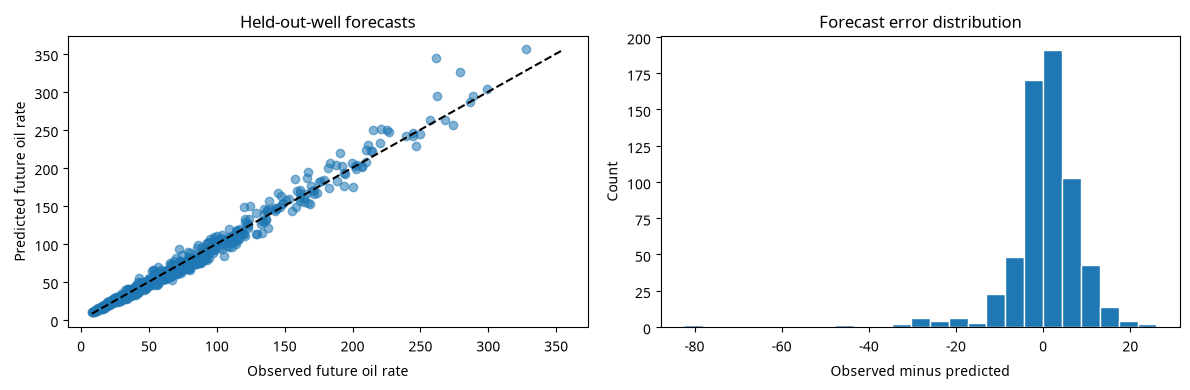

In [10]:
results = test_df[["well_id", "date", "reservoir_type", "region", "oil_rate", target]].copy()
results["prediction"] = pred
results["error"] = results[target] - results["prediction"]
results["absolute_error"] = results["error"].abs()
display(results.sort_values("absolute_error", ascending=False).head(20))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test, pred, alpha=.55)
lo, hi = min(y_test.min(), pred.min()), max(y_test.max(), pred.max())
axes[0].plot([lo, hi], [lo, hi], "--", color="black")
axes[0].set(xlabel="Observed future oil rate", ylabel="Predicted future oil rate", title="Held-out-well forecasts")
axes[1].hist(results.error.dropna(), bins=25, edgecolor="white")
axes[1].set(xlabel="Observed minus predicted", ylabel="Count", title="Forecast error distribution")
plt.tight_layout()
plt.show()

## 10. Well-history visualization and pressure scope
These plots present observed sample histories. The starter model predicts oil rate only. Pressure forecasting must be trained and validated as a separate target using pressure measurements with units and consistent semantics; no pressure accuracy is reported in this first notebook.

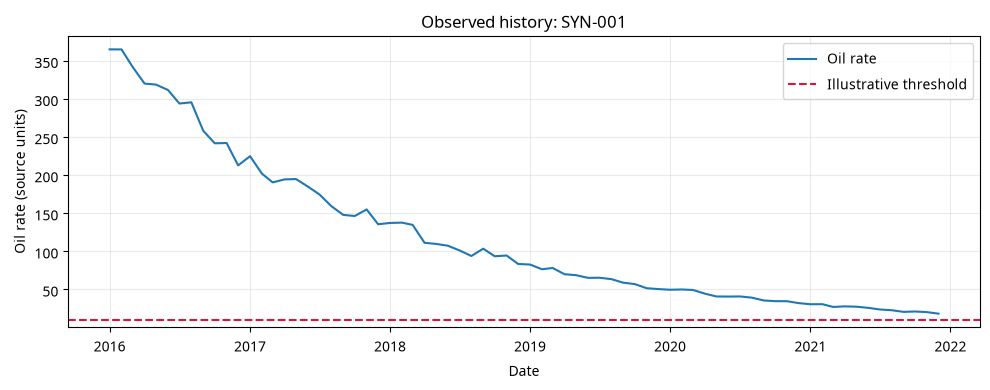

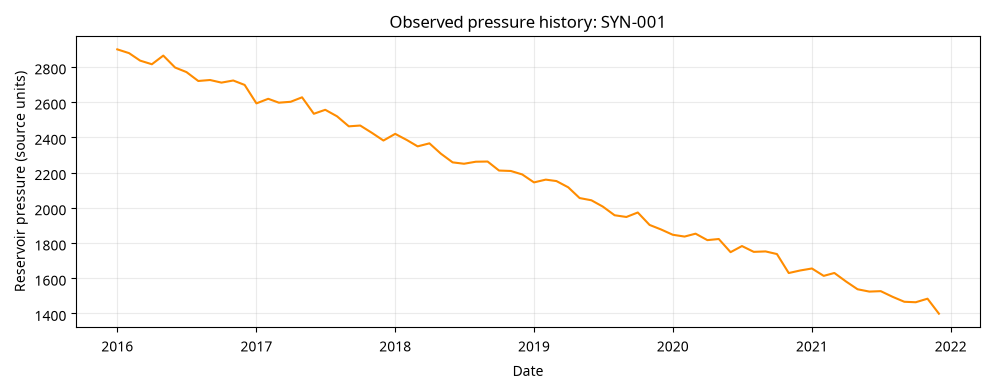

In [11]:
sample_well = df.well_id.iloc[0]
well = df[df.well_id == sample_well].sort_values("date")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(well.date, well.oil_rate, label="Oil rate")
ax.axhline(NATURAL_FLOW_THRESHOLD, color="crimson", linestyle="--", label="Illustrative threshold")
ax.set(title=f"Observed history: {sample_well}", xlabel="Date", ylabel="Oil rate (source units)")
ax.legend(); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
if "reservoir_pressure" in well:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(well.date, well.reservoir_pressure, color="darkorange")
    ax.set(title=f"Observed pressure history: {sample_well}", xlabel="Date", ylabel="Reservoir pressure (source units)")
    ax.grid(alpha=.25); plt.tight_layout(); plt.show()

## 11. Exporting the first dashboard-style report tables
This cell writes predictions and metrics to `reports/`. These tables are reproducible outputs, not field recommendations. Add prediction intervals, subgroup metrics, drift checks, and a documented threshold review before presenting project conclusions.

In [12]:
report_dir = PROJECT_ROOT / "reports"
report_dir.mkdir(exist_ok=True)
results.to_csv(report_dir / "demo_predictions.csv", index=False)
metrics_table.to_csv(report_dir / "demo_metrics.csv", index=False)
print("Saved demonstration outputs under", report_dir)

Saved demonstration outputs under /home/ubuntu/solution-gas-drive-ml/reports


## 12. Interpretation and next validation requirements
The demonstration metrics only indicate whether code executed on synthetic data. They must not appear in project conclusions as model accuracy. Before model acceptance, the team should assemble licensed field histories, document reservoir drive mechanism, normalize units, define natural-flow failure/threshold and censored wells, record interventions and shut-ins, test unseen-well and forward-time splits, compare against persistence and engineering decline baselines, quantify intervals/calibration, and review performance by reservoir type and region. If 30 eligible well histories cannot be sourced, report the limitation rather than inflating the sample with synthetic wells.